# Groupe 21 — Agriculture
**Étudiants :** Bellouchi Marwa, Imene Bouhou  
**Scénario :** Analyse de la production agricole selon les régions et les cultures à partir du dataset ICRISAT.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Configuration de l'affichage des graphiques dans Jupyter
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.autolayout": True})

# Chargement du fichier ICRISAT
df = pd.read_csv("ICRISAT-District Level Data.csv")

# Affichage des premières lignes pour vérifier les colonnes
print("Aperçu des données :")
display(df.head())

# Nettoyage de base des valeurs manquantes
df = df.dropna()

Aperçu des données :


,Dist Code,Year,State Code,State Name,Dist Name,RICE AREA (1000 ha),RICE PRODUCTION (1000 tons),RICE YIELD (Kg per ha),WHEAT AREA (1000 ha),WHEAT PRODUCTION (1000 tons),...,SUGARCANE YIELD (Kg per ha),COTTON AREA (1000 ha),COTTON PRODUCTION (1000 tons),COTTON YIELD (Kg per ha),FRUITS AREA (1000 ha),VEGETABLES AREA (1000 ha),FRUITS AND VEGETABLES AREA (1000 ha),POTATOES AREA (1000 ha),ONION AREA (1000 ha),FODDER AREA (1000 ha)
0,1,1966,14,Chhattisgarh,Durg,548.0,185.0,337.59,44.0,20.0,...,1777.78,0.0,0.0,0.0,5.95,6.64,12.59,0.01,0.60,0.47
1,1,1967,14,Chhattisgarh,Durg,547.0,409.0,747.71,50.0,26.0,...,1500.00,0.0,0.0,0.0,5.77,7.24,13.02,0.01,0.56,1.23
2,1,1968,14,Chhattisgarh,Durg,556.3,468.0,841.27,53.7,30.0,...,1000.00,0.0,0.0,0.0,5.41,7.40,12.81,0.10,0.58,1.02
3,1,1969,14,Chhattisgarh,Durg,563.4,400.8,711.40,49.4,26.5,...,1900.00,0.0,0.0,0.0,5.52,7.16,12.69,0.01,0.56,0.84
4,1,1970,14,Chhattisgarh,Durg,571.6,473.6,828.55,44.2,29.0,...,2000.00,0.0,0.0,0.0,5.45,7.19,12.64,0.02,0.52,0.42


### 1. Quelles cultures ont la production la plus importante, et dans quelles régions ?

Top des cultures les plus productives :


,Crop,Total_Production
0,RICE PRODUCTION (1000 tons),3631066.91
1,WHEAT PRODUCTION (1000 tons),2938777.79
21,SUGARCANE PRODUCTION (1000 tons),1219213.15
20,OILSEEDS PRODUCTION (1000 tons),821989.98
6,MAIZE PRODUCTION (1000 tons),582115.18
4,SORGHUM PRODUCTION (1000 tons),459537.00
5,PEARL MILLET PRODUCTION (1000 tons),357231.66
12,GROUNDNUT PRODUCTION (1000 tons),355707.45
2,KHARIF SORGHUM PRODUCTION (1000 tons),296409.79
9,CHICKPEA PRODUCTION (1000 tons),291378.87


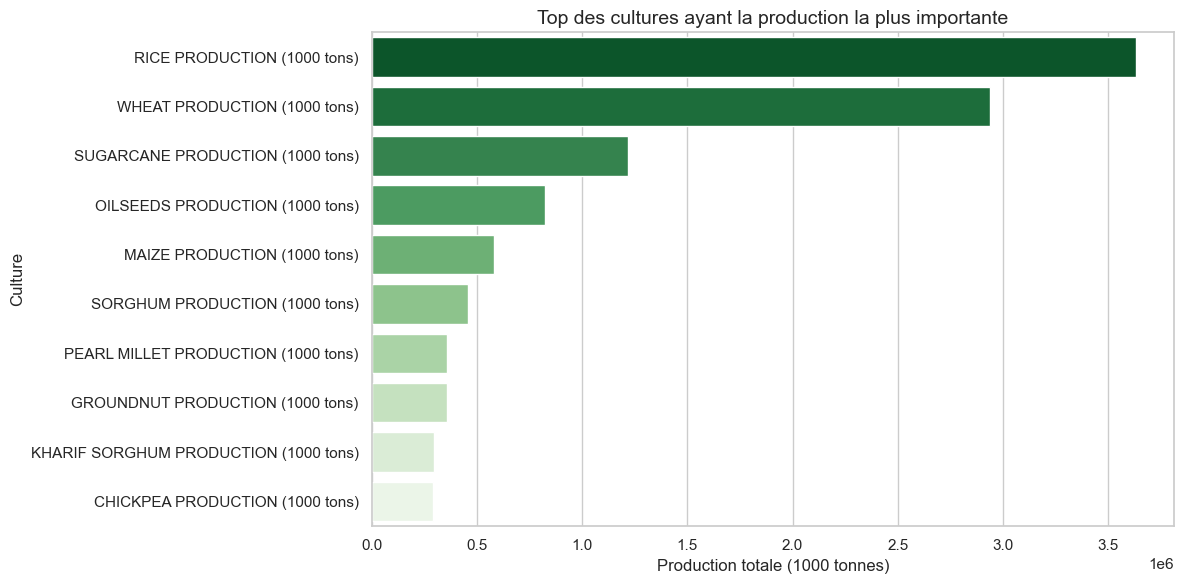


Régions (États) principales pour la culture principale : RICE PRODUCTION (1000 tons)


,State Name,RICE PRODUCTION (1000 tons)
19,West Bengal,544232.26
17,Uttar Pradesh,445597.62
13,Punjab,335040.10
0,Andhra Pradesh,315185.40
15,Tamil Nadu,291201.51


In [2]:
# Sélectionner les colonnes de production (qui contiennent 'PRODUCTION' dans leur nom)
production_cols = [col for col in df.columns if "PRODUCTION" in col]

# Calculer la production totale pour chaque culture dans tout le pays
total_prod_by_crop = df[production_cols].sum().reset_index()
total_prod_by_crop.columns = ["Crop", "Total_Production"]
total_prod_by_crop = total_prod_by_crop.sort_values(
    by="Total_Production", ascending=False
)

print("Top des cultures les plus productives :")
display(total_prod_by_crop.head(10))

# Visualisation du Top des cultures
plt.figure(figsize=(12, 6))
sns.barplot(
    data=total_prod_by_crop.head(10),
    x="Total_Production",
    y="Crop",
    hue="Crop",
    palette="Greens_r",
    legend=False,
)
plt.title("Top des cultures ayant la production la plus importante", fontsize=14)
plt.xlabel("Production totale (1000 tonnes)")
plt.ylabel("Culture")
plt.show()

# Exemple pour la culture principale (la première de la liste)
top_crop_col = total_prod_by_crop.iloc[0]["Crop"]
print(f"\nRégions (États) principales pour la culture principale : {top_crop_col}")

# Regrouper par État ('State Name') pour voir quelles régions produisent le plus cette culture
top_regions_crop = (
    df.groupby("State Name")[top_crop_col].sum().reset_index()
)
top_regions_crop = top_regions_crop.sort_values(
    by=top_crop_col, ascending=False
)
display(top_regions_crop.head())

### 2. Comment la production a-t-elle évolué dans le temps pour les cultures principales ?

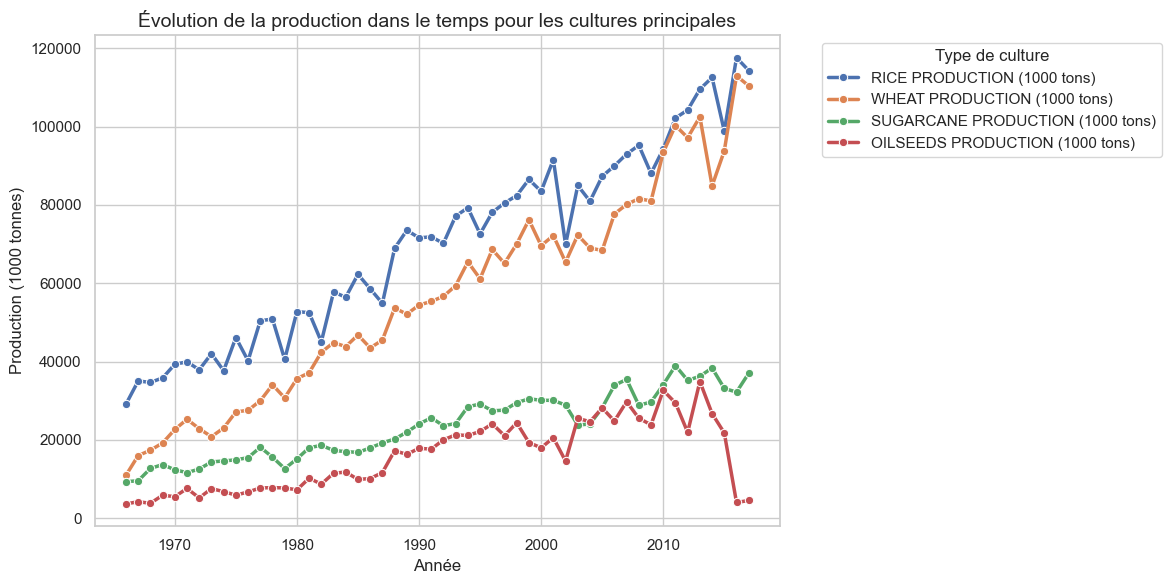

In [3]:
# Sélectionner les 3 ou 4 principales colonnes de production
top_crops_cols = total_prod_by_crop["Crop"].head(4).tolist()

# Grouper par année ('Year') et sommer la production pour ces cultures
evolution_df = df.groupby("Year")[top_crops_cols].sum().reset_index()

# Transformer le tableau pour l'affichage avec Seaborn (melt)
evolution_melted = evolution_df.melt(
    id_vars=["Year"],
    value_vars=top_crops_cols,
    var_name="Crop",
    value_name="Production",
)

# Graphique de l'évolution
plt.figure(figsize=(12, 6))
sns.lineplot(
    data=evolution_melted,
    x="Year",
    y="Production",
    hue="Crop",
    marker="o",
    linewidth=2.5,
)
plt.title(
    "Évolution de la production dans le temps pour les cultures principales",
    fontsize=14,
)
plt.xlabel("Année")
plt.ylabel("Production (1000 tonnes)")
plt.legend(title="Type de culture", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.show()

### 3. Le rendement (production par surface) varie-t-il beaucoup selon les régions ?

Analyse du rendement pour : RICE YIELD (Kg per ha)


,State Name,mean,median,std
13,Punjab,3100.420350,3200.315,874.955305
15,Tamil Nadu,2813.897420,2774.175,1042.029425
0,Andhra Pradesh,2337.551014,2249.425,824.889842
5,Haryana,2188.078434,2372.570,951.990121
16,Telangana,2179.698547,2190.445,732.740888
8,Karnataka,2151.539757,2204.760,754.279029
9,Kerala,1929.976027,1876.220,485.827726
19,West Bengal,1865.334716,1818.190,733.426846
17,Uttar Pradesh,1575.101480,1619.000,688.732436
1,Assam,1362.419038,1302.755,444.693184


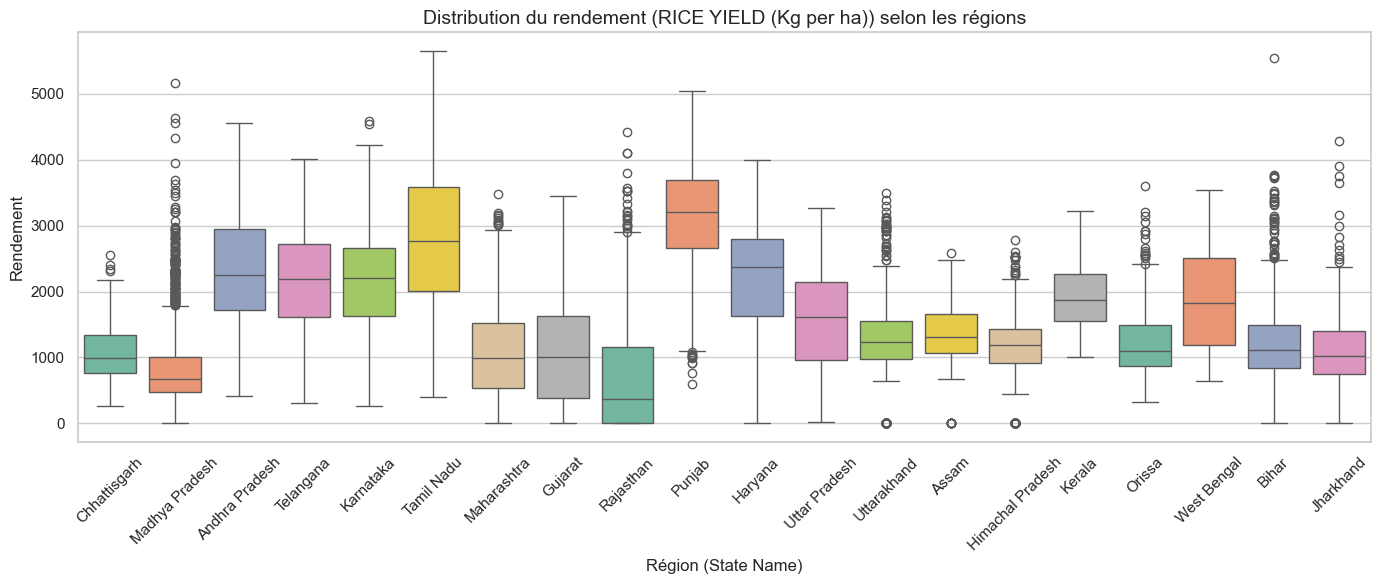

In [4]:
# Identifier une colonne de rendement (ex: 'RICE YIELD (Kg per ha)')
yield_cols = [col for col in df.columns if "YIELD" in col]

if len(yield_cols) > 0:
    main_yield_col = yield_cols[
        0
    ]  # On prend la première par exemple (ex: Riz)
    print(f"Analyse du rendement pour : {main_yield_col}")

    # Calcul des statistiques de rendement par État (Région)
    region_yield = (
        df.groupby("State Name")[main_yield_col]
        .agg(["mean", "median", "std"])
        .reset_index()
        .sort_values(by="mean", ascending=False)
    )
    display(region_yield.head(10))

    # Boîte à moustaches (Boxplot) des rendements par région
    plt.figure(figsize=(14, 6))
    sns.boxplot(
        data=df,
        x="State Name",
        y=main_yield_col,
        hue="State Name",
        palette="Set2",
        legend=False,
    )
    plt.title(
        f"Distribution du rendement ({main_yield_col}) selon les régions",
        fontsize=14,
    )
    plt.xlabel("Région (State Name)")
    plt.ylabel("Rendement")
    plt.xticks(rotation=45)
    plt.show()
else:
    print("Aucune colonne de rendement spécifique trouvée.")

### 4. Quelles recommandations feriez-vous pour orienter la politique agricole régionale ?

In [5]:
print("--- SYNTHÈSE DES RECOMMANDATIONS POUR LA POLITIQUE AGRICOLE ---")
print(
    "1. Soutien ciblé aux régions sous-performantes : Utiliser l'analyse des rendements par État pour identifier les zones ayant un écart-type ou une moyenne faible afin d'y injecter des aides à l'irrigation et aux intrants.\n"
    "2. Adaptation climatique : S'appuyer sur les courbes d'évolution temporelle pour identifier les cultures dont la production stagne ou chute, et encourager la transition vers des variétés plus résilientes.\n"
    "3. Optimisation des surfaces : Réallouer stratégiquement les surfaces cultivées en fonction des rendements régionaux constatés pour maximiser la production globale sans épuiser les sols."
)

--- SYNTHÈSE DES RECOMMANDATIONS POUR LA POLITIQUE AGRICOLE ---
1. Soutien ciblé aux régions sous-performantes : Utiliser l'analyse des rendements par État pour identifier les zones ayant un écart-type ou une moyenne faible afin d'y injecter des aides à l'irrigation et aux intrants.
2. Adaptation climatique : S'appuyer sur les courbes d'évolution temporelle pour identifier les cultures dont la production stagne ou chute, et encourager la transition vers des variétés plus résilientes.
3. Optimisation des surfaces : Réallouer stratégiquement les surfaces cultivées en fonction des rendements régionaux constatés pour maximiser la production globale sans épuiser les sols.
